<a href="https://colab.research.google.com/github/iofeii/svd-image-compression/blob/main/notebooks/02_svd_approximation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
A = data.camera().astype(float)
print(A.shape, A.dtype)

(512, 512) float64


Loaded necessary libraries and imported an image from skimage which we named A and converted from uint8 to float type. Then we printed how many rows and coulms were in A.

In [4]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print("U:", U.shape, "s:", s.shape, "Vt:", Vt.shape)

A_back = U @ np.diag(s) @ Vt
print("Rebuilt correctly?", np.allclose(A, A_back))
print("Largest error:", np.abs(A - A_back).max())

U: (512, 512) s: (512,) Vt: (512, 512)
Rebuilt correctly? True
Largest error: 2.538058652135078e-11


I had to insert quotation marks around labels because otherwise the code errored. The breaks down matrix A into U, s, and Vt. Then it prints out the dimensions of the shapes. Afterwards, it rebuilds the original matrix via matrix multiplication. np.diag(s) turns the 1D array (s) into a diagnal matrix. Finally, it checks to make sure the matrix is close to the original matrix and finds the absolute difference between every corresponding elements in both matrices. The largest error is printed.

First five: [70966.  17054.6 13314.9  8837.4  5874.6]
50th, 200th, last: 757.2 175.5 0.006


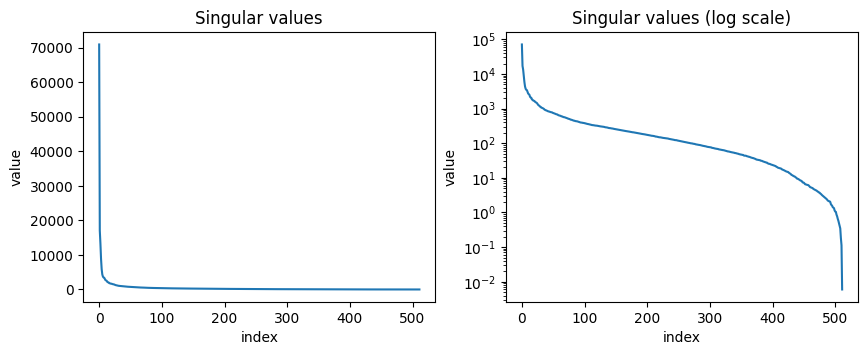

In [8]:
print("First five:", np.round(s[:5], 1))
print("50th, 200th, last:", round(s[49], 1),
round(s[199], 1), round(s[-1], 3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(s)
ax1.set(title="Singular values", xlabel="index", ylabel="value")
ax2.semilogy(s)
ax2.set(title="Singular values (log scale)", xlabel="index", ylabel="value")
plt.show()

I had to add the quotation marks for the printed labels, otherwise it would error. This block of code prints the first five single values. Then it prints the 50th, 200th, and last signuar value. It then creates side-by-side plots with one showing the singualr values on a linear scale and another showing the values on a log scale. This is helpful because the log scale makes the smaller values visible.

In [9]:
def rank_k_approx(A, k):
  """Return the rank-k SVD approximation of A."""
  U, s, Vt = np.linalg.svd(A, full_matrices=False)
  return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

I added the quotation marks again to make sure the code ran without error. This block of code breaks down matrix A into singular vectors U, s, and Vt again. Then, it only returns the largest singular values and their corresponding vectors. Specifically, the first k columns of U, the first k rows of Vt, and a diagnoal matrix using the first k largest singular values. Then the matrix is rebuilt with matrix multiplication, but it is compressed.

In [10]:
print("rank of A_10:", np.linalg.matrix_rank(rank_k_approx(A, 10)))
print("k = 512 gives A back?", np.allclose(rank_k_approx(A, 512), A))

stripes = np.outer([1, 0, 1, 0], [1, 1, 1, 1]).astype(float)
print("singular values of stripes:",
  np.round(np.linalg.svd(stripes, compute_uv=False), 4))

rank of A_10: 10
k = 512 gives A back? True
singular values of stripes: [2.8284 0.     0.     0.    ]


Added quotes again.
This code runs checks to show that A10 has rank 10 (matrix after compression). Then it checks if using k = 512 componenets fully rebuilds the non-compressed matrix. After that, it calculates only the single values of the stripes matrix and rounds them to the nearest 4 decimal places to see how many dominant components this pattern has.

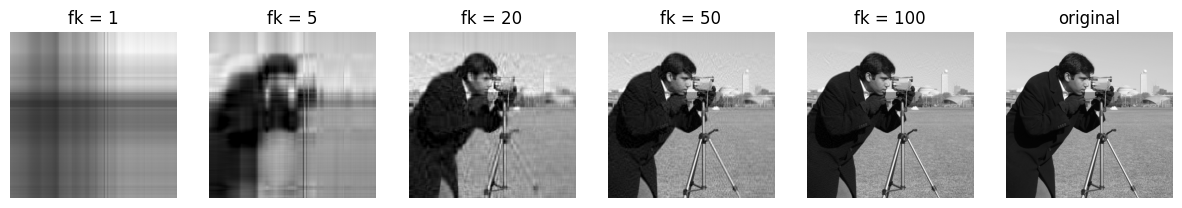

In [22]:
ks = [1, 5, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))
for ax, k in zip(axes, ks):
  Ak = np.clip(rank_k_approx(A, k), 0, 255)
  ax.imshow(Ak, cmap="gray", vmin=0, vmax=255)
  ax.set_title(f"fk = {k}")
  ax.axis("off")

axes[-1].imshow(A, cmap="gray", vmin=0, vmax=255)
axes[-1].set_title("original")
axes[-1].axis("off")
plt.show()

I had to fill in missing quotation marks and place an f infront of fk={k} to properly format it. We make an array of different k values. The smaller the value, the less data is stored. Then we make a row of subplots for each k value along with the original inamge. We make sure the pixels are in grayscale after matrix operations and render each image.

In [ ]:
# Excercise 1

